In [4]:
from pathlib import Path
import os

project_root = Path.cwd()

# If the notebook is inside notebooks/, move one level up
if project_root.name == "notebooks":
    project_root = project_root.parent

os.chdir(project_root)
print("Current working directory:")
print(os.getcwd())

Current working directory:
/home/anshul/crop-disease-detection


In [5]:
import json
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    "data/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

valid_data = tf.keras.utils.image_dataset_from_directory(
    "data/valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_data.class_names

print("Number of classes:", len(class_names))
print(class_names[:5])

Found 70295 files belonging to 38 classes.


W0000 00:00:1795610479.962020   15415 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1795610480.290112   10050 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Found 17572 files belonging to 38 classes.
Number of classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [6]:
import os

os.makedirs("models", exist_ok=True)

with open("models/class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved to models/class_names.json")

Class names saved to models/class_names.json


In [7]:
import tensorflow as tf
AUTOTUNE = tf.data.AUTOTUNE

def normalize(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_data = train_data.map(
    normalize,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

valid_data = valid_data.map(
    normalize,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Images normalized and datasets are ready.")

Images normalized and datasets are ready.


In [8]:
for images, labels in train_data.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel value range:", images.numpy().min(), "to", images.numpy().max())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel value range: 0.0 to 1.0


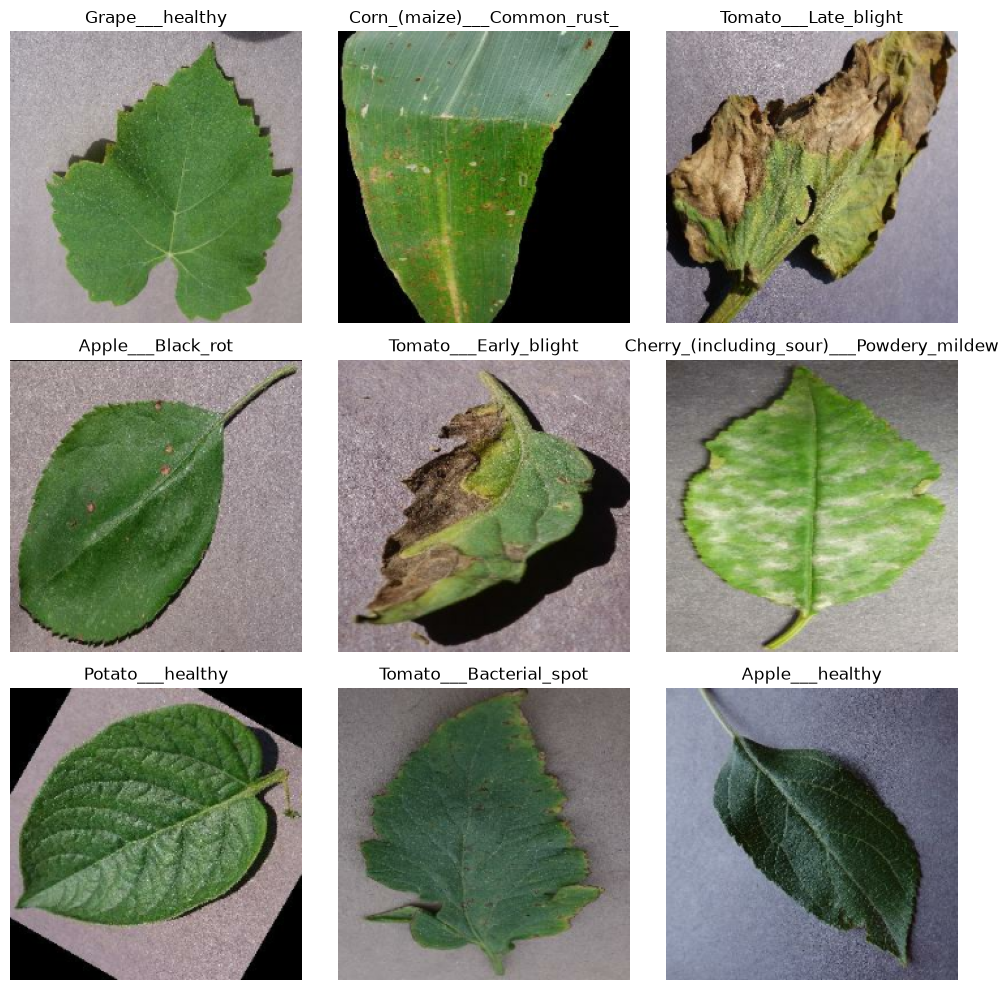

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_data.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()